<a href="https://colab.research.google.com/github/M-Hadi-Hidayat/Tugas-Machine-Learning/blob/main/Tugas%201%20Muhammad%20Hadi%20Hidayat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset dengan nama file yang benar
df = pd.read_csv('dataset_tugas1_preprocessing (1).csv')
print("--- 5 Baris Pertama Dataset ---")
print(df.head())

--- 5 Baris Pertama Dataset ---
      ID  Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
0  MH001  Iwan     Laki-laki  Teknik Komputer  Aktif         NaN   
1  MH002   Eka     Perempuan  Teknik Komputer  Lulus           E   
2  MH003  Iwan     Laki-laki  Teknik Komputer  Aktif         NaN   
3  MH004   Eka     Perempuan  Teknik Komputer  Aktif           D   
4  MH005  Joko     Perempuan     Data Science  Aktif           C   

  Tanggal_Ujian  Umur  
0    13-04-2020   NaN  
1    2020/12/11  28.0  
2    2021/11/21  23.0  
3    2021/08/19  18.0  
4    2020/01/05  26.0  


In [ ]:
# Cek struktur dan tipe data
print("\n--- Informasi Struktur dan Tipe Data ---")
print(df.info())

# Tampilkan jumlah nilai hilang per kolom
print("\n--- Jumlah Nilai Hilang per Kolom ---")
print(df.isnull().sum())

# Sajikan statistik deskriptif
print("\n--- Statistik Deskriptif ---")
print(df.describe(include='all'))


--- Informasi Struktur dan Tipe Data ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB
None

--- Jumlah Nilai Hilang per Kolom ---
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

--- Statistik Deskriptif ---
           ID Nama Jenis_Kelamin            Prodi Status Nilai_Akhir  \
count      99   99            99             

In [ ]:
# Imputasi Umur dengan Median
if 'Umur' in df.columns:
    df['Umur'] = df['Umur'].fillna(df['Umur'].median())

# Imputasi Nilai_Akhir berdasarkan tipe data
if 'Nilai_Akhir' in df.columns:
    if pd.api.types.is_numeric_dtype(df['Nilai_Akhir']):
        df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mean())
    else:
        df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mode()[0])

print("\n--- Cek Missing Values Setelah Imputasi ---")
print(df.isnull().sum())


--- Cek Missing Values Setelah Imputasi ---
ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64


In [ ]:

# Mengubah string kosong menjadi missing value
df = df.replace(r'^\s*$', np.nan, regex=True)

# Mengisi missing value pada Nilai_Akhir menggunakan modus
if df["Nilai_Akhir"].isnull().any():
    modus_nilai = df["Nilai_Akhir"].mode()
    if not modus_nilai.empty:
        df["Nilai_Akhir"] = df["Nilai_Akhir"].fillna(
            modus_nilai.iloc[0]
        )

# Mengisi missing value pada Umur menggunakan median
df["Umur"] = pd.to_numeric(df["Umur"], errors="coerce")

if df["Umur"].isnull().any():
    median_umur = df["Umur"].median()
    if pd.notna(median_umur):
        df["Umur"] = df["Umur"].fillna(median_umur)

# Memeriksa hasil imputasi
print("Missing values setelah imputasi:")
print(df[["Nilai_Akhir", "Umur"]].isnull().sum())

display(df[["Nilai_Akhir", "Umur"]].head())

Missing values setelah imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64


,Nilai_Akhir,Umur
0,C,23.0
1,E,28.0
2,C,23.0
3,D,18.0
4,C,26.0


In [ ]:

# Mengonversi kolom Tanggal_Ujian ke datetime
df["Tanggal_Ujian"] = pd.to_datetime(
    df["Tanggal_Ujian"],
    errors="coerce",
    dayfirst=True
)

# Memeriksa tipe data dan hasil konversi
print("Tipe data Tanggal_Ujian:")
print(df["Tanggal_Ujian"].dtype)

print("\nContoh data tanggal:")
display(df[["Tanggal_Ujian"]].head())

print("\nJumlah tanggal yang tidak berhasil dikonversi:")
print(df["Tanggal_Ujian"].isnull().sum())

Tipe data Tanggal_Ujian:
datetime64[ns]

Contoh data tanggal:


,Tanggal_Ujian
0,2020-04-13
1,NaT
2,NaT
3,NaT
4,NaT



Jumlah tanggal yang tidak berhasil dikonversi:
89


In [ ]:

# Kolom yang akan di-encoding
kolom_kategorikal = [
    "Nama",
    "Jenis_Kelamin",
    "Prodi",
    "Status",
    "Nilai_Akhir"
]

# Menyimpan encoder untuk setiap kolom
label_encoders = {}

for kolom in kolom_kategorikal:
    # Memastikan tidak ada missing value pada kolom kategori
    df[kolom] = df[kolom].fillna("Tidak diketahui").astype(str)

    # Melakukan Label Encoding
    encoder = LabelEncoder()
    df[kolom] = encoder.fit_transform(df[kolom])

    label_encoders[kolom] = encoder

# Menampilkan hasil encoding
print("Data setelah Label Encoding:")
display(df[kolom_kategorikal].head())

# Menampilkan pemetaan kategori menjadi angka
for kolom, encoder in label_encoders.items():
    print(f"\nPemetaan kolom {kolom}:")
    print(dict(zip(
        encoder.classes_,
        encoder.transform(encoder.classes_)
    )))

Data setelah Label Encoding:


,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir
0,8,0,3,0,2
1,4,1,3,3,4
2,8,0,3,0,2
3,4,1,3,0,3
4,9,1,0,0,2



Pemetaan kolom Nama:
{'Adi': np.int64(0), 'Budi': np.int64(1), 'Citra': np.int64(2), 'Dina': np.int64(3), 'Eka': np.int64(4), 'Farhan': np.int64(5), 'Gita': np.int64(6), 'Hana': np.int64(7), 'Iwan': np.int64(8), 'Joko': np.int64(9)}

Pemetaan kolom Jenis_Kelamin:
{'Laki-laki': np.int64(0), 'Perempuan': np.int64(1)}

Pemetaan kolom Prodi:
{'Data Science': np.int64(0), 'Informatika': np.int64(1), 'Sistem Informasi': np.int64(2), 'Teknik Komputer': np.int64(3)}

Pemetaan kolom Status:
{'Aktif': np.int64(0), 'Cuti': np.int64(1), 'DO': np.int64(2), 'Lulus': np.int64(3)}

Pemetaan kolom Nilai_Akhir:
{'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2), 'D': np.int64(3), 'E': np.int64(4)}


In [ ]:

# Memisahkan fitur dan target belum dilakukan karena
# kolom target belum ditentukan dalam instruksi tugas.

# Membagi seluruh dataset menjadi data latih dan data uji
data_latih, data_uji = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Jumlah seluruh data:", len(df))
print("Jumlah data latih:", len(data_latih))
print("Jumlah data uji:", len(data_uji))

print("\nProporsi data latih:",
      round(len(data_latih) / len(df) * 100, 2), "%")
print("Proporsi data uji:",
      round(len(data_uji) / len(df) * 100, 2), "%")

print("\nContoh data latih:")
display(data_latih.head())

print("Contoh data uji:")
display(data_uji.head())

Jumlah seluruh data: 99
Jumlah data latih: 79
Jumlah data uji: 20

Proporsi data latih: 79.8 %
Proporsi data uji: 20.2 %

Contoh data latih:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
49,MH050,4,1,1,2,2,NaT,21.0
70,MH071,5,0,1,2,2,2021-08-15,19.0
68,MH069,7,1,1,1,1,NaT,24.0
15,MH016,4,0,2,3,4,NaT,19.0
39,MH040,2,0,1,1,2,NaT,29.0


Contoh data uji:


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
62,MH063,4,1,0,1,3,NaT,25.0
40,MH041,6,0,3,2,2,2021-03-26,22.0
95,MH096,0,0,2,3,2,NaT,20.0
18,MH019,5,1,1,2,2,NaT,25.0
97,MH098,4,1,0,0,0,NaT,22.0


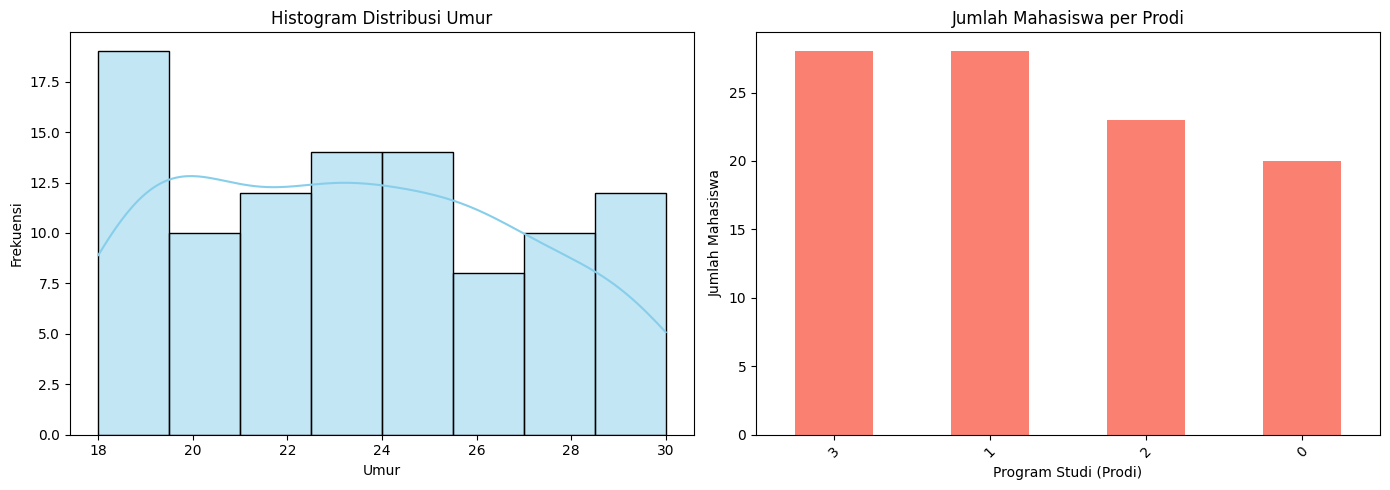

In [ ]:
plt.figure(figsize=(14, 5))

# 1. Histogram untuk kolom Umur
plt.subplot(1, 2, 1)
sns.histplot(df['Umur'], kde=True, color='skyblue')
plt.title('Histogram Distribusi Umur')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

# 2. Grafik batang jumlah mahasiswa per Prodi
plt.subplot(1, 2, 2)
df['Prodi'].value_counts().plot(kind='bar', color='salmon')
plt.title('Jumlah Mahasiswa per Prodi')
plt.xlabel('Program Studi (Prodi)')
plt.ylabel('Jumlah Mahasiswa')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()